**New benchmark analysis (2026-10-05).** Uses the available 4L/2H/K16 checkpoints with weight decay **0.1**, seeds 100–104. This is a new exploratory analysis, not reproduction of SEL-4L wd0.01. References/conflict definitions are frozen historical inputs, verified by hash. All model-dependent outputs are recomputed. Validation match splits support the stated comparisons; prior test access prevents a fresh confirmatory claim. Population and intervention scope apply to each reported result. See `config/analysis_plan.json` and `SURGICAL_FIXES.md`.

# MB11 — Faithfulness, Specificity and Cross-Seed Replication

**Track B · Mechanistic interpretability of SEL-4L · Identity × Context project**

| Item | Content |
|---|---|
| **Question** | Is the candidate circuit necessary and sufficient for the behaviour, specific to it rather than general damage, and does the same functional structure appear in the other four checkpoints? |
| **Experiments** | E19 (faithfulness), E20 (replication across seeds) |
| **Inputs** | `config/circuit.json` (fingerprint checked); MB02 reference means |
| **Population** | P-player validation, estimation half; matched controls; index-0 rows; scored validation events for NLL; discovery half only for matching heads across seeds |
| **Outputs** | `results/MB11_faithfulness.csv`, `results/MB11_minimality.csv`, `results/MB11_random_circuits.csv`, `results/MB11_specificity.csv`, `results/MB11_replication.csv`, `results/MB11_head_matching.csv`, `results/MB11_summary.json`, `figures/MB11_*` |
| **Modules** | uses `circuits.py`, `patching.py` |
| **Test data** | none |



> **⚠ REPAIR STATUS (2026-10-04).** Three review findings bear on this notebook:
> * **F08** (limitation, not a code bug): the circuit holds 11 of 12 components, so the size-matched random-circuit control
>   has only C(8,7)·C(4,4) = **8 distinct** alternatives (which head to leave out). "100 random circuits" are 100 draws with
>   replacement from those 8. The original tables are kept; **Section R1** enumerates the 8 exactly for every seed.
>   "F not above the random 95th percentile" (0 of 4 replicates; MB12 M2 on test) remains a **valid negative result**.
> * **F09**: every F and completeness value here is **component-set** faithfulness (components kept with all their
>   connections). It does not validate MB10's selected **edge graph**. **Section R2** tests the identity-contrast edge graph
>   directly.
> * F values near 1 with nearly the whole network retained do not show that a sparse mechanism has been found.

In [1]:
import os
for _thread_var in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ[_thread_var] = os.environ.get("MI_CPU_THREADS", "4")
import sys
import json
import time
import importlib
import importlib.util
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")


def find_root(start):
    """`start` (or one of its ancestors) holding both project folders directly, else None."""
    start = Path(start).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "model_training_evaluation").is_dir() and (candidate / "mi_analysis").is_dir():
            return candidate
    return None


def search_root(bases, max_depth=6):
    """Breadth-first search under each base (e.g. a mounted Drive) for the project root."""
    for base in bases:
        base = Path(base)
        if not base.is_dir():
            continue
        found = find_root(base)
        if found is not None:
            return found
        frontier = [(base, 0)]
        while frontier:
            folder, depth = frontier.pop(0)
            if depth >= max_depth:
                continue
            try:
                children = [c for c in folder.iterdir() if c.is_dir() and not c.name.startswith(".")]
            except PermissionError:
                continue
            for child in children:
                if child.name == "model_training_evaluation" and (child.parent / "mi_analysis").is_dir():
                    return child.parent
                frontier.append((child, depth + 1))
    return None


if "SOCCER_MI_ROOT" in os.environ:
    ROOT = Path(os.environ["SOCCER_MI_ROOT"])
elif IN_COLAB:
    ROOT = search_root(["/content", "/content/drive/MyDrive", "/content/drive/My Drive"])
    if ROOT is None:
        raise RuntimeError(
            "BLOCKED: could not find a folder holding both model_training_evaluation/ and mi_analysis/ "
            "under /content or the mounted Drive. Upload or sync the project there, or set "
            "SOCCER_MI_ROOT to its exact path in a cell ABOVE this one, for example: "
            "import os; os.environ['SOCCER_MI_ROOT'] = '/content/drive/MyDrive/.../soccer_mi'")
else:
    ROOT = find_root(Path.cwd())
    if ROOT is None:
        raise RuntimeError(f"BLOCKED: no ancestor of {Path.cwd()} holds both model_training_evaluation/ "
                           "and mi_analysis/. Run this notebook from inside the project, or set SOCCER_MI_ROOT.")
TRACK_A_DIR = ROOT / "model_training_evaluation"
MI_DIR = Path(os.environ.get("MI_ANALYSIS_DIR", ROOT / "mi_analysis")).resolve()
assert (TRACK_A_DIR / "src" / "data.py").exists(), (
    f"BLOCKED: {TRACK_A_DIR / 'src' / 'data.py'} not found -- ROOT resolved to {ROOT}, which is wrong. "
    "Set SOCCER_MI_ROOT explicitly.")
assert (TRACK_A_DIR / "artifacts" / "events_prepared.parquet").exists(), (
    f"BLOCKED: {TRACK_A_DIR / 'artifacts' / 'events_prepared.parquet'} not found -- ROOT is wrong.")
RUN_MODE = os.environ.get("MI_RUN_MODE", "full")
assert RUN_MODE in ("full", "smoke")

for folder in [MI_DIR, MI_DIR / "src", MI_DIR / "notebooks", MI_DIR / "tests"]:
    folder.mkdir(parents=True, exist_ok=True)
(MI_DIR / "src" / "__init__.py").touch()
os.chdir(MI_DIR)

sys.path[:] = [entry for entry in sys.path if entry not in ("", ".", str(MI_DIR))]
if str(TRACK_A_DIR) not in sys.path:
    sys.path.insert(0, str(TRACK_A_DIR))
spec = importlib.util.spec_from_file_location("mi_src", MI_DIR / "src" / "__init__.py",
                                              submodule_search_locations=[str(MI_DIR / "src")])
mi_src = importlib.util.module_from_spec(spec)
sys.modules["mi_src"] = mi_src
spec.loader.exec_module(mi_src)

print("Colab:", IN_COLAB, "| RUN_MODE:", RUN_MODE)
print("ROOT:", ROOT)
print("Track A (read only):", TRACK_A_DIR, "| exists:", TRACK_A_DIR.exists())
print("Track B:", MI_DIR)

Colab: True | RUN_MODE: full
ROOT: /content/soccer_mi
Track A (read only): /content/soccer_mi/model_training_evaluation | exists: True
Track B: /content/soccer_mi/.mi_analysis_rerun


In [2]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

import src.data as data
import src.metrics as metrics
import src.training as training
import mi_src.paths as paths
import mi_src.fingerprint as fingerprint
import mi_src.mi_setup as mi_setup
import mi_src.hooks as hooks
import mi_src.interventions as interventions
import mi_src.mi_metrics as mi_metrics
import mi_src.patching as patching
import mi_src.circuits as circuits
for module in [data, metrics, training, paths, fingerprint, mi_setup, hooks, interventions, mi_metrics, patching, circuits]:
    importlib.reload(module)

if getattr(paths, "SCHEMA_VERSION", 1) < 2:
    raise RuntimeError("BLOCKED: mi_analysis/src/paths.py is older than this notebook expects. "
                       "Re-run MB01 section 0 (its three %%writefile cells), then restart the kernel.")
paths.check_modules(**{name: module for name, module in
                       [("paths", paths), ("fingerprint", fingerprint), ("mi_setup", mi_setup),
                        ("patching", globals().get("patching")), ("circuits", globals().get("circuits"))]
                       if module is not None})

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

OUT = paths.output_dir(MI_DIR, RUN_MODE)
SETTINGS = paths.RUN_SETTINGS[RUN_MODE]
TRACK = paths.track_a_paths(TRACK_A_DIR)
MANIFEST = OUT / "manifests" / "sha_manifest.json"
REGISTRY = OUT / "manifests" / "experiment_registry.jsonl"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
torch.set_num_threads(int(os.environ.get("MI_CPU_THREADS", "4")))
if RUN_MODE == "full" and DEVICE != "cuda":
    print("Note: no GPU found. The full run works on CPU but is much slower.")
training.configure_determinism()
training.set_seed(0)
ACTIONS = list(data.ACTION_NAMES)
print("Device:", DEVICE, "| outputs:", OUT)
print("Settings:", SETTINGS)

Device: cuda | outputs: /content/soccer_mi/.mi_analysis_rerun
Settings: {'reference_epochs': 25, 'batch_windows': 256, 'n_bootstrap': 2000, 'n_draws': 5, 'n_permutations': 1000, 'n_random_circuits': 100, 'probe_train_events': 20000, 'max_events': 100000, 'probe_seeds': 3, 'scrub_draws': 5}


In [3]:
verified = fingerprint.verify_files(MANIFEST)
prereg = mi_setup.load_json(OUT / "config" / "preregistration.json")
mi_config = mi_setup.load_json(OUT / "config" / "mi_config.json")
IDENTITY = mi_config["identity_variable"]
PRIMARY_SEED = int(prereg["model"]["primary_seed"])


def run_dir(seed):
    """Run directory of one SEL-4L seed, re-rooted onto this checkout."""
    return paths.rebase_run_dir(prereg["model"]["run_dirs"][str(seed)], TRACK["root"])

SEEDS = [int(seed) for seed in prereg["model"]["run_dirs"]]
N_BOOT = SETTINGS["n_bootstrap"]
BATCH = SETTINGS["batch_windows"]

events = pd.read_parquet(TRACK["events"])
bundle = mi_setup.build_bundle(events, TRACK, DEVICE)
val_view = bundle["views"]["val"]
targets = bundle["targets"]
POP = OUT / "artifacts" / "populations"
val_conflicts = pd.read_parquet(POP / "val_conflicts.parquet")
controls = pd.read_parquet(POP / "matched_controls.parquet")
MODEL = mi_setup.load_model(run_dir(PRIMARY_SEED), bundle)
N_LAYERS = len(MODEL.blocks)
N_HEADS = MODEL.blocks[0].attention.n_heads
print(f"verified files: {len(verified)} | primary seed {PRIMARY_SEED} | identity variable: {IDENTITY}")
print(val_conflicts.groupby(["population", "half"]).size().unstack().to_string())
from scipy.optimize import linear_sum_assignment

circuit = mi_setup.load_json(OUT / "config" / "circuit.json")
CIRCUIT = circuit["components"]
ALL = circuits.all_components(N_LAYERS, N_HEADS)
HEADS = [c for c in ALL if not c.endswith("MLP")]
partners = pd.read_parquet(POP / "swap_partners.parquet")
partner_of = dict(zip(partners["player"], partners["partner"]))
reference = torch.load(POP / "reference_means.pt", map_location="cpu", weights_only=False)
MEANS = {site: value.to(DEVICE) for site, value in reference["means"].items()}
REFERENCE_WINDOWS = np.asarray(reference["windows"])
p_player = val_conflicts[val_conflicts.population == "P-player"].reset_index(drop=True)
estimation = p_player[p_player.half == "estimation"].reset_index(drop=True)
discovery = p_player[p_player.half == "discovery"].reset_index(drop=True)
index0 = val_conflicts[val_conflicts.population == "index-0"].reset_index(drop=True)
nll_table = circuits.scored_events(val_view, targets, bundle["match_ids"],
                                   limit=None if RUN_MODE == "full" else SETTINGS["max_events"] * 3)
RUN = len(CIRCUIT) > 0
print(f"circuit: {CIRCUIT} | source: {circuit['source']} | code check only: {circuit['code_check_only']}")
print(f"estimation-half P-player rows: {len(estimation):,}" + ("" if RUN else " | the circuit is empty: E19-E20 are skipped"))

/content/soccer_mi/model_training_evaluation/src/batching.py:19: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  self.tensors[name] = torch.as_tensor(np.asarray(values), device=device)


verified files: 63 | primary seed 103 | identity variable: player
half        discovery  estimation
population                       
P-player         1215         529
index-0          4296        4651
circuit: ['L0H0', 'L0H1', 'L0MLP', 'L1H0', 'L1H1', 'L1MLP', 'L2H0', 'L2H1', 'L2MLP', 'L3H1', 'L3MLP'] | source: discovery-selected MB06 candidates + estimation-half exact edges passing BH; exploratory benchmark | code check only: False
estimation-half P-player rows: 529


## 1. Terms

| Term | Meaning here |
|---|---|
| **Faithfulness F (sufficiency)** | How much of the behaviour the circuit alone reproduces when every other head and MLP is mean-ablated. |
| **Completeness** | Whether removing the circuit removes the behaviour. |
| **Minimality** | Whether every part of the circuit is needed: F after dropping one component. |
| **Specificity** | Whether removing the circuit changes this behaviour more than unrelated predictions. |
| **Functional matching of heads** | Pairing each head of a replicate model with the head of seed 103 whose ablation affects the same events in the same way, instead of assuming that head L2H1 does the same job in every model. |

## 2. Two behaviours, measured separately

1. **Identity effect:** Δ_clean − Δ_I1 per event (how much the player moves the arbitration); under an ablation the same ablation is applied to both runs.
2. **Arbitration:** Δ itself on the recorded events.

## 3. E19 — Faithfulness runs (mean ablation at every position)

| Run | What is mean-ablated | Measure |
|---|---|---|
| Full | nothing | m_full |
| Circuit only | every head and MLP not in the circuit | m_circuit |
| Empty | every head and MLP | m_empty |
| Circuit removed | the circuit's heads and MLPs | m_removed |

```latex
F = \frac{m_{circuit} - m_{empty}}{m_{full} - m_{empty}}, \qquad \text{completeness} = 1 - \frac{m_{removed} - m_{empty}}{m_{full} - m_{empty}}
```

Both are pooled ratios over events, each event aligned by the sign of its own m_full − m_empty (as for recovery in MB06), with match-bootstrap intervals (Wang et al. 2023; Conmy et al. 2023). Also reported: the per-event correlation of Δ between the full and the circuit-only run, and the share of events on which the two agree in sign.

In [4]:
def remove_player(inputs, positions, chunk):
    return interventions.remove_feature(inputs, IDENTITY, positions)

def run_measures(model, means, table, ablated, method="mean", generator=None):
    """Identity effect and Delta per event with `ablated` components removed at every position."""
    if method == "mean":
        builder = circuits.mean_ablation(ablated, means, at_target=False)
    else:
        builder = circuits.resample_ablation(model, bundle, val_view, REFERENCE_WINDOWS, ablated, False, generator)
    clean, corrupt = circuits.identity_effects(model, bundle, val_view, table, BATCH, remove_player, builder)
    return {"identity effect": clean - corrupt, "arbitration": clean}

def faithfulness(model, means, table, circuit_components, method="mean", n_repeats=1, seed=0):
    generator = torch.Generator().manual_seed(seed)
    runs = {}
    for name, ablated in [("full", []), ("circuit only", [c for c in ALL if c not in circuit_components]),
                          ("empty", ALL), ("removed", list(circuit_components))]:
        measures = [run_measures(model, means, table, ablated, method, generator) for _ in range(n_repeats if ablated else 1)]
        runs[name] = {key: np.mean([m[key] for m in measures], axis=0) for key in measures[0]}
    return runs

def scores(runs, match_ids, behaviour):
    full, circ, empty, removed = (runs[k][behaviour] for k in ["full", "circuit only", "empty", "removed"])
    f = mi_metrics.pooled_recovery(circ - empty, full - empty, match_ids, N_BOOT)
    kept = mi_metrics.pooled_recovery(removed - empty, full - empty, match_ids, N_BOOT)
    return {"behaviour": behaviour, "F": f["recovery"], "F CI low": f["ci_low"], "F CI high": f["ci_high"],
            "completeness": 1 - kept["recovery"], "completeness CI low": 1 - kept["ci_high"], "completeness CI high": 1 - kept["ci_low"],
            "mean m_full": full.mean(), "mean m_circuit": circ.mean(), "mean m_empty": empty.mean(), "mean m_removed": removed.mean(),
            "r(full, circuit only)": float(np.corrcoef(full, circ)[0, 1]) if full.std() > 0 and circ.std() > 0 else np.nan,
            "sign agreement": float((np.sign(full) == np.sign(circ)).mean())}

faith_rows = []
if RUN:
    start = time.time()
    primary_runs = faithfulness(MODEL, MEANS, estimation, CIRCUIT)
    for behaviour in ["identity effect", "arbitration"]:
        faith_rows.append({"method": "mean", **scores(primary_runs, estimation["match_id"].to_numpy(), behaviour)})
    resample_runs = faithfulness(MODEL, MEANS, estimation, CIRCUIT, method="resample", n_repeats=SETTINGS["n_draws"])
    for behaviour in ["identity effect", "arbitration"]:
        faith_rows.append({"method": "resample", **scores(resample_runs, estimation["match_id"].to_numpy(), behaviour)})
    print(f"done in {time.time() - start:.0f} s")
faith = pd.DataFrame(faith_rows)
faith.to_csv(OUT / "results" / "MB11_faithfulness.csv", index=False)
print(faith.round(4).T.to_string() if len(faith) else "skipped: empty circuit")

done in 2 s
                                     0            1                2            3
method                            mean         mean         resample     resample
behaviour              identity effect  arbitration  identity effect  arbitration
F                               1.0114       0.9864           1.0181       0.9793
F CI low                        0.9979       0.9842           1.0007       0.9767
F CI high                       1.0272       0.9879           1.0354       0.9812
completeness                    0.9949       0.9989           0.9984       1.0048
completeness CI low             0.9907        0.997           0.9937       0.9896
completeness CI high             0.998       1.0004           1.0014       1.0233
mean m_full                    -0.1672       5.8937          -0.1672       5.8937
mean m_circuit                 -0.1713        5.709          -0.1736       5.6708
mean m_empty                     0.009      -7.6991          -0.0028      -4.8828
mean

**Resample check.** The second pair of columns repeats every run with resample ablation (`n_draws` draws): removed components take their values from random other validation windows instead of the reference mean. F and completeness that change sign or size a lot between the two methods depend on how "removed" is defined.

### Minimality

For each circuit component, F of the circuit without that component (the dropped component is mean-ablated with everything else outside the circuit). A component whose removal barely lowers F is not needed for sufficiency.

In [5]:
minimal_rows = []
if RUN and len(CIRCUIT) > 1:
    for component in CIRCUIT:
        reduced = [c for c in CIRCUIT if c != component]
        runs = dict(primary_runs)
        measures = run_measures(MODEL, MEANS, estimation, [c for c in ALL if c not in reduced])
        runs["circuit only"] = measures
        for behaviour in ["identity effect", "arbitration"]:
            result = scores(runs, estimation["match_id"].to_numpy(), behaviour)
            full_f = faith.loc[(faith.method == "mean") & (faith.behaviour == behaviour), "F"].iloc[0]
            minimal_rows.append({"dropped component": component, "behaviour": behaviour, "F without it": result["F"],
                                 "CI low": result["F CI low"], "CI high": result["F CI high"], "drop in F": full_f - result["F"]})
minimality = pd.DataFrame(minimal_rows)
minimality.to_csv(OUT / "results" / "MB11_minimality.csv", index=False)
print(minimality.round(4).to_string(index=False) if len(minimality) else "minimality needs at least two components")

dropped component       behaviour  F without it  CI low  CI high  drop in F
             L0H0 identity effect        0.9683  0.9116   1.0337     0.0431
             L0H0     arbitration        0.9838  0.9783   0.9887     0.0026
             L0H1 identity effect        0.9986  0.9701   1.0505     0.0128
             L0H1     arbitration        0.9768  0.9725   0.9800     0.0096
            L0MLP identity effect        0.5124  0.4277   0.6204     0.4990
            L0MLP     arbitration        0.4858  0.4428   0.5494     0.5006
             L1H0 identity effect        0.9915  0.9633   1.0344     0.0199
             L1H0     arbitration        0.9849  0.9802   0.9883     0.0015
             L1H1 identity effect        0.9711  0.9442   0.9932     0.0402
             L1H1     arbitration        0.9967  0.9934   0.9994    -0.0103
            L1MLP identity effect        0.6757  0.5392   0.8330     0.3357
            L1MLP     arbitration        0.6210  0.5885   0.6512     0.3655
            

> **⚠ REPAIR NOTE (2026-10-04) — VALID — INTERPRETATION NARROWED — F08.** The draws below come from only 8 distinct component sets (each head left out once), drawn with replacement; the percentile is over draws, not over 100 architectures. Exact enumeration: Section R1.

### Random-circuit control

`n_random_circuits` random circuits with the same number of heads and MLPs as the candidate circuit (drawn from all layers). The candidate's F is reported as a percentile of that distribution; a circuit that is not better than random sets of the same size does not single out the mechanism.

/tmp/ipykernel_10095/3790024347.py:4: UserWarning: random_circuits: 100 draws requested but only 8 distinct size-matched sets exist; draws repeat (sampling with replacement).
  for index, components in enumerate(circuits.random_circuits(ALL, CIRCUIT, SETTINGS["n_random_circuits"], seed=0)):


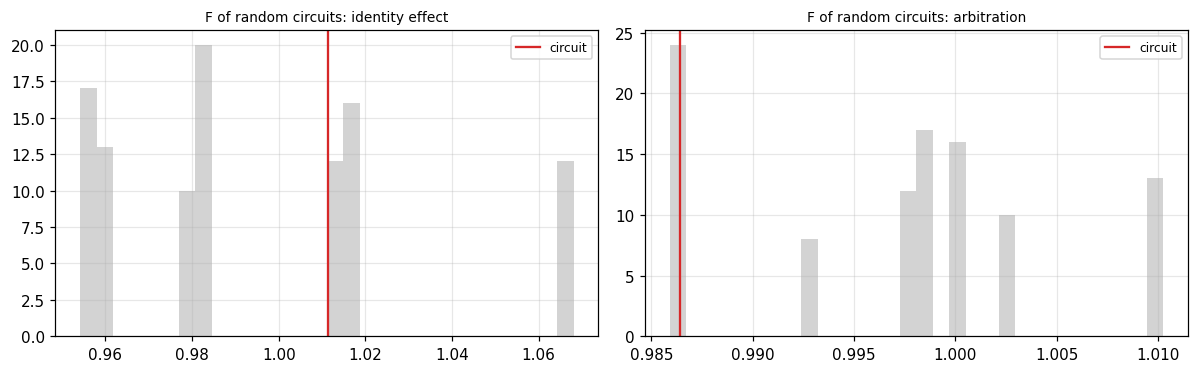

      behaviour  F (circuit)  random median  random 95th percentile  percentile of circuit  n random
identity effect       1.0114         0.9811                  1.0681                   60.0       100
    arbitration       0.9864         0.9983                  1.0103                   12.0       100


In [6]:
random_rows = []
if RUN:
    full_runs = {k: primary_runs[k] for k in ["full", "empty"]}
    for index, components in enumerate(circuits.random_circuits(ALL, CIRCUIT, SETTINGS["n_random_circuits"], seed=0)):
        measures = run_measures(MODEL, MEANS, estimation, [c for c in ALL if c not in components])
        row = {"draw": index, "components": "+".join(components)}
        for behaviour in ["identity effect", "arbitration"]:
            row[f"F ({behaviour})"] = mi_metrics.pooled_ratio(measures[behaviour] - full_runs["empty"][behaviour],
                                                              full_runs["full"][behaviour] - full_runs["empty"][behaviour])
        random_rows.append(row)
random_circuits = pd.DataFrame(random_rows)
random_circuits.to_csv(OUT / "results" / "MB11_random_circuits.csv", index=False)
percentile_rows = []
if RUN:
    for behaviour in ["identity effect", "arbitration"]:
        distribution = random_circuits[f"F ({behaviour})"].dropna().to_numpy()
        value = faith.loc[(faith.method == "mean") & (faith.behaviour == behaviour), "F"].iloc[0]
        percentile_rows.append({"behaviour": behaviour, "F (circuit)": value, "random median": float(np.median(distribution)),
                                "random 95th percentile": float(np.percentile(distribution, 95)),
                                "percentile of circuit": float((distribution < value).mean() * 100), "n random": len(distribution)})
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    for axis, behaviour in zip(axes, ["identity effect", "arbitration"]):
        axis.hist(random_circuits[f"F ({behaviour})"].dropna(), bins=30, color="lightgrey")
        axis.axvline(faith.loc[(faith.method == "mean") & (faith.behaviour == behaviour), "F"].iloc[0], color="tab:red", label="circuit")
        axis.set_title(f"F of random circuits: {behaviour}", fontsize=9); axis.legend(fontsize=8)
    plt.tight_layout(); plt.savefig(OUT / "figures" / "MB11_random_circuits.png", bbox_inches="tight"); plt.show()
percentiles = pd.DataFrame(percentile_rows)
print(percentiles.round(4).to_string(index=False) if len(percentiles) else "skipped")

### Specificity

With the circuit removed (mean ablation at every position): the change in Δ on P-player conflicts, on their matched controls and on index-0 conflicts, and the change in NLL of the true action on scored validation events. Specificity per pair = |change on the conflict| − |change on its control|, with a one-sided p-value (greater).

In [7]:
specificity = pd.DataFrame()
if RUN:
    panel = circuits.AblationPanel(MODEL, bundle, val_view, {"P-player": p_player, "matched controls": controls, "index-0": index0},
                                   nll_table, BATCH)
    changes, nll_change = panel.changes(lambda: circuits.mean_ablation(CIRCUIT, MEANS, False))
    specificity = circuits.summarise_ablation(panel.rows("circuit", "mean", "all positions", changes, nll_change), controls, N_BOOT)
    specificity.to_csv(OUT / "results" / "MB11_specificity.csv", index=False)
    print(specificity.round(4).T.to_string())
else:
    print("skipped")

                                              0
unit                                    circuit
method                                     mean
scope                             all positions
NLL (scored events): mean change         2.7555
NLL (scored events): CI low              2.6627
NLL (scored events): CI high             2.8474
P-player: mean change                  -13.5779
P-player: CI low                       -13.8396
P-player: CI high                      -13.2032
P-player: p                               0.001
index-0: mean change                   -13.8078
index-0: CI low                        -14.1268
index-0: CI high                       -13.4765
matched controls: mean change           -9.5334
matched controls: CI low               -10.2891
matched controls: CI high               -8.5907
specificity: mean                        2.1433
specificity: CI low                      1.4384
specificity: CI high                     3.0411
specificity: n pairs                    

**Researcher interpretation** *(written by the researcher after reading the numbers above; the code never writes these words)*

- What was tested:
- Why it was tested:
- What was observed:
- What the result supports:
- What it contradicts:
- Alternative explanations that remain:
- What it does not establish:
- Evidence label (Observed / Supported / Strong causal evidence / Hypothesized):

## 4. E20 — Replication across the four other seeds

**Question.** Does the same *functional* structure appear in the other SEL-4L checkpoints?

**Rerun on each replicate:** MB03's mean Δ on P-all (estimation half); MB04's E5 (|ΔΔ| under the matched swap minus under the norm-matched random vector); the MB06 sweep for the primary identity contrast (pooled recovery per site at the target, denoising, discovery half), compared with seed 103 site by site; MB07's single-head mean ablations; and E19 with the replicate's own matched circuit and its own random circuits.

**Matching components by function, not index.** On the discovery half, every head's vector of per-event changes in Δ under mean ablation (every position) is correlated with every head of seed 103; heads are paired by maximum total correlation (Hungarian assignment). MLPs are matched by layer. The replicate's matched circuit is the image of seed 103's circuit under that pairing; each replicate's reference means are recomputed on the same 2,000 reference windows.

**Reported:** per seed, F and its interval, the matching correlations, and how many of the four replicates have F above their own random-circuit 95th percentile. The count is reported as is; no "replicates if ≥ k" rule is applied.

In [8]:
def run_dir(seed):
    """Run directory of one SEL-4L seed, re-rooted onto this checkout."""
    return paths.rebase_run_dir(prereg["model"]["run_dirs"][str(seed)], TRACK["root"])


ablation_sites = [f"{kind}_{l}" for l in range(N_LAYERS) for kind in ["head_z", "mlp_out", "attn_out"]]
SWEEP = [(label, site, head) for label, site, head in patching.sweep_sites(N_LAYERS, N_HEADS)]
all_estimation = val_conflicts[val_conflicts.half == "estimation"].reset_index(drop=True)

def head_effects(model, means):
    intact = circuits.deltas(model, bundle, val_view, discovery, BATCH)
    return {head: circuits.deltas(model, bundle, val_view, discovery, BATCH, circuits.mean_ablation([head], means, False)) - intact
            for head in HEADS}

def sweep_recovery(model):
    rows = []
    with torch.no_grad():
        for part, inputs, positions, a_ctx, a_id in mi_setup.event_batches(bundle, val_view, discovery, BATCH):
            corrupted = interventions.remove_feature(inputs, IDENTITY, positions)
            m_clean, m_corrupt, patched = patching.patch_batch(model, inputs, corrupted, positions, a_ctx, a_id, SWEEP, [0], ["denoise"])
            for (_, label, _), values in patched.items():
                rows.append(pd.DataFrame({"site": label, "num": values - m_corrupt, "den": m_clean - m_corrupt}))
    frame = pd.concat(rows)
    ratios = {site: mi_metrics.pooled_ratio(group["num"], group["den"]) for site, group in frame.groupby("site", sort=False)}
    return pd.Series(ratios).reindex([label for label, _, _ in SWEEP])

@torch.no_grad()
def e5_difference(model, seed=0):
    generator = torch.Generator().manual_seed(seed)
    values = []
    for part, inputs, positions, a_ctx, a_id in mi_setup.event_batches(bundle, val_view, estimation, BATCH):
        chunk = estimation.iloc[part]
        base = mi_metrics.delta(mi_metrics.at_target(hooks.forward(model, inputs)[0], positions), a_ctx, a_id)
        own = chunk["player"].to_numpy(); partner = np.array([partner_of.get(p, -1) for p in own])
        swapped = interventions.set_feature(inputs, "player", positions, torch.as_tensor(np.where(partner > 0, partner, own), device=DEVICE))
        swap = np.abs(circuits.delta_under(model, swapped, positions, a_ctx, a_id) - base)
        vector = np.mean([np.abs(circuits.delta_under(model, inputs, positions, a_ctx, a_id,
                                                       {"factor_player": interventions.norm_matched_vector(None, positions, generator)}) - base)
                          for _ in range(SETTINGS["n_draws"])], axis=0)
        values.append(np.where(partner > 0, swap - vector, np.nan))
    values = np.concatenate(values)
    keep = ~np.isnan(values)
    return mi_metrics.summarise(values[keep], estimation["match_id"].to_numpy()[keep], N_BOOT)

replication_rows, matching_rows = [], []
if RUN and IDENTITY == "player":
    start = time.time()
    primary_heads = head_effects(MODEL, MEANS)
    primary_sweep = sweep_recovery(MODEL)
    for seed in SEEDS:
        model = MODEL if seed == PRIMARY_SEED else mi_setup.load_model(run_dir(seed), bundle)
        means = MEANS if seed == PRIMARY_SEED else mi_setup.reference_means(model, bundle, val_view, REFERENCE_WINDOWS, ablation_sites,
                                                                            BATCH, hooks.forward)
        if seed == PRIMARY_SEED:
            mapping = {head: head for head in HEADS}
        else:
            effects = head_effects(model, means)
            correlation = np.array([[np.corrcoef(primary_heads[a], effects[b])[0, 1] if primary_heads[a].std() > 0 and effects[b].std() > 0 else 0.0
                                     for b in HEADS] for a in HEADS])
            rows_index, cols_index = linear_sum_assignment(-np.nan_to_num(correlation))
            mapping = {HEADS[r]: HEADS[c] for r, c in zip(rows_index, cols_index)}
            for r, c in zip(rows_index, cols_index):
                matching_rows.append({"seed": seed, "seed-103 head": HEADS[r], "matched head": HEADS[c], "correlation": correlation[r, c]})
        matched = sorted(mapping.get(c, c) for c in CIRCUIT)
        delta_all = circuits.deltas(model, bundle, val_view, all_estimation, BATCH)
        delta_summary = mi_metrics.summarise(delta_all, all_estimation["match_id"], N_BOOT)
        e5 = e5_difference(model)
        sweep = sweep_recovery(model)
        runs = faithfulness(model, means, estimation, matched)
        result = scores(runs, estimation["match_id"].to_numpy(), "identity effect")
        random_f = []
        for components in circuits.random_circuits(ALL, matched, SETTINGS["n_random_circuits"], seed=seed):
            measures = run_measures(model, means, estimation, [c for c in ALL if c not in components])
            random_f.append(mi_metrics.pooled_ratio(measures["identity effect"] - runs["empty"]["identity effect"],
                                                    runs["full"]["identity effect"] - runs["empty"]["identity effect"]))
        random_f = np.array(random_f, dtype=float)
        replication_rows.append({"seed": seed, "primary": seed == PRIMARY_SEED, "matched circuit": "+".join(matched),
                                 "mean Delta (P-all, estimation)": delta_summary["mean"], "Delta CI low": delta_summary["ci_low"],
                                 "Delta CI high": delta_summary["ci_high"], "E5 mean difference": e5["mean"], "E5 CI low": e5["ci_low"],
                                 "E5 CI high": e5["ci_high"],
                                 "sweep r with seed 103": float(np.corrcoef(primary_sweep.fillna(0), sweep.fillna(0))[0, 1]),
                                 "F (identity effect)": result["F"], "F CI low": result["F CI low"], "F CI high": result["F CI high"],
                                 "own random 95th percentile": float(np.nanpercentile(random_f, 95)),
                                 "F above own random 95th percentile": bool(result["F"] > np.nanpercentile(random_f, 95)),
                                 "completeness": result["completeness"]})
        if seed != PRIMARY_SEED:
            del model
        print(f"seed {seed} done ({time.time() - start:.0f} s)")
replication = pd.DataFrame(replication_rows)
matching = pd.DataFrame(matching_rows)
replication.to_csv(OUT / "results" / "MB11_replication.csv", index=False)
matching.to_csv(OUT / "results" / "MB11_head_matching.csv", index=False)
if len(replication):
    print(replication.round(4).T.to_string())
    replicates = replication[~replication["primary"]]
    print(f"replicates with F above their own random-circuit 95th percentile: {int(replicates['F above own random 95th percentile'].sum())} of {len(replicates)}")
    print(matching.round(3).to_string(index=False))
else:
    print("skipped")

/tmp/ipykernel_10095/739672645.py:72: UserWarning: random_circuits: 100 draws requested but only 8 distinct size-matched sets exist; draws repeat (sampling with replacement).
  for components in circuits.random_circuits(ALL, matched, SETTINGS["n_random_circuits"], seed=seed):


seed 100 done (10 s)


/tmp/ipykernel_10095/739672645.py:72: UserWarning: random_circuits: 100 draws requested but only 8 distinct size-matched sets exist; draws repeat (sampling with replacement).
  for components in circuits.random_circuits(ALL, matched, SETTINGS["n_random_circuits"], seed=seed):


seed 101 done (18 s)


/tmp/ipykernel_10095/739672645.py:72: UserWarning: random_circuits: 100 draws requested but only 8 distinct size-matched sets exist; draws repeat (sampling with replacement).
  for components in circuits.random_circuits(ALL, matched, SETTINGS["n_random_circuits"], seed=seed):


seed 102 done (27 s)


/tmp/ipykernel_10095/739672645.py:72: UserWarning: random_circuits: 100 draws requested but only 8 distinct size-matched sets exist; draws repeat (sampling with replacement).
  for components in circuits.random_circuits(ALL, matched, SETTINGS["n_random_circuits"], seed=seed):


seed 103 done (33 s)


/tmp/ipykernel_10095/739672645.py:72: UserWarning: random_circuits: 100 draws requested but only 8 distinct size-matched sets exist; draws repeat (sampling with replacement).
  for components in circuits.random_circuits(ALL, matched, SETTINGS["n_random_circuits"], seed=seed):


seed 104 done (42 s)
                                                                                             0                                                           1                                                           2                                                           3                                                           4
seed                                                                                       100                                                         101                                                         102                                                         103                                                         104
primary                                                                                  False                                                       False                                                       False                                                        True                                   

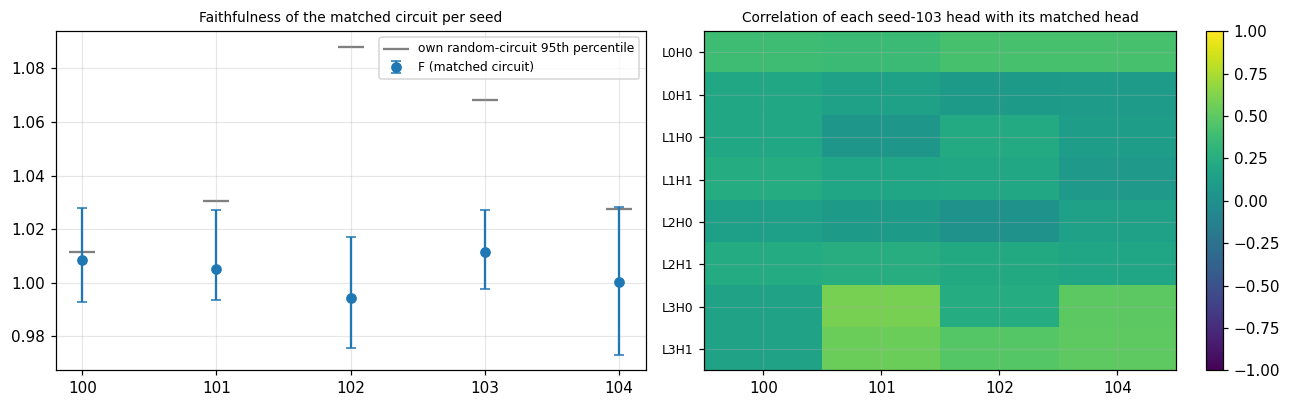

In [9]:
if len(replication):
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
    axes[0].errorbar(replication["seed"].astype(str), replication["F (identity effect)"],
                     yerr=[replication["F (identity effect)"] - replication["F CI low"], replication["F CI high"] - replication["F (identity effect)"]],
                     fmt="o", capsize=3, label="F (matched circuit)")
    axes[0].scatter(replication["seed"].astype(str), replication["own random 95th percentile"], marker="_", s=300, color="grey",
                    label="own random-circuit 95th percentile")
    axes[0].set_title("Faithfulness of the matched circuit per seed", fontsize=9); axes[0].legend(fontsize=8)
    if len(matching):
        grid = matching.pivot(index="seed-103 head", columns="seed", values="correlation").reindex(HEADS)
        image = axes[1].imshow(grid.to_numpy(), cmap="viridis", vmin=-1, vmax=1, aspect="auto")
        axes[1].set_yticks(range(len(HEADS))); axes[1].set_yticklabels(HEADS, fontsize=8)
        axes[1].set_xticks(range(grid.shape[1])); axes[1].set_xticklabels(grid.columns)
        axes[1].set_title("Correlation of each seed-103 head with its matched head", fontsize=9); plt.colorbar(image, ax=axes[1])
    plt.tight_layout(); plt.savefig(OUT / "figures" / "MB11_replication.png", bbox_inches="tight"); plt.show()

**Researcher interpretation** *(written by the researcher after reading the numbers above; the code never writes these words)*

- What was tested:
- Why it was tested:
- What was observed:
- What the result supports:
- What it contradicts:
- Alternative explanations that remain:
- What it does not establish:
- Evidence label (Observed / Supported / Strong causal evidence / Hypothesized):

## 5. Hand-off to MB12

The researcher now writes the mechanism statement and its quantitative predictions for the test set in MB12 Section 1 (template there). No test data is touched in this notebook.

In [10]:
mi_setup.save_json(OUT / "results" / "MB11_summary.json", {
    "circuit": circuit, "faithfulness": faith.to_dict(orient="records"), "minimality": minimality.to_dict(orient="records"),
    "random_percentiles": percentiles.to_dict(orient="records"), "specificity": specificity.to_dict(orient="records"),
    "replication": replication.to_dict(orient="records"), "skipped": not RUN, "run_mode": RUN_MODE})
fingerprint.record_files(MANIFEST, {"results/MB11_summary.json": OUT / "results" / "MB11_summary.json"})
fingerprint.register(REGISTRY, {"notebook": "MB11", "experiment": "E19-E20 faithfulness and replication", "seed": PRIMARY_SEED,
                                "circuit": CIRCUIT, "skipped": not RUN, "run_mode": RUN_MODE})
print("saved")

saved


## R. Corrections (REPAIR 2026-10-04)

### R1 — The size-matched random-circuit space, enumerated exactly (F08)

For the primary seed and every replicate: the number of distinct size-matched component sets, F (identity effect,
mean ablation, estimation half) of **each** of them once, and where the circuit ranks among them. This replaces "percentile
among 100 draws" by an exact statement over the whole space. It does not change the circuit.

In [11]:
import importlib
try:
    import mi_src.scrub as scrub
    import mi_src.steering as steering
    import mi_src.context_edits as context_edits
    import mi_src.graph as graph
except ModuleNotFoundError as error:
    raise RuntimeError("BLOCKED: the repaired modules (scrub, steering, context_edits, graph) are missing. Run "
                       "MB07R_repaired_sources_and_regression_tests.ipynb, then restart the kernel.") from error
for module in [hooks, mi_metrics, circuits, scrub, steering, context_edits, graph]:
    importlib.reload(module)
for module in [circuits, mi_metrics, scrub, steering, context_edits, graph]:
    if getattr(module, "REPAIR_VERSION", None) != "2026-10-04":
        raise RuntimeError(f"BLOCKED: {module.__name__} on disk is not the repaired 2026-10-04 version. Re-run the repaired "
                           "%%writefile cells (MB02 for mi_metrics, MB07 for circuits, MB07R for the new modules), then restart.")
print("repaired modules loaded:", [m.__name__ for m in [circuits, mi_metrics, scrub, steering, context_edits, graph]])

space = circuits.random_circuit_space(ALL, CIRCUIT)
print("size-matched space for the primary circuit:", space)
if len(random_circuits):
    draw_counts = random_circuits["components"].value_counts()
    print(f"original draws: {len(random_circuits)} draws, {len(draw_counts)} distinct sets, each drawn {draw_counts.min()}-{draw_counts.max()} times; "
          f"the circuit itself drawn {int(draw_counts.get('+'.join(sorted(CIRCUIT)), 0))} times")

distinct_rows = []
if RUN:
    for seed in SEEDS:
        model = MODEL if seed == PRIMARY_SEED else mi_setup.load_model(run_dir(seed), bundle)
        means = MEANS if seed == PRIMARY_SEED else mi_setup.reference_means(model, bundle, val_view, REFERENCE_WINDOWS, ablation_sites, BATCH, hooks.forward)
        matched = CIRCUIT if seed == PRIMARY_SEED else replication.loc[replication["seed"] == seed, "matched circuit"].iloc[0].split("+")
        base_runs = faithfulness(model, means, estimation, matched)
        full_effect = base_runs["full"]["identity effect"]
        empty_effect = base_runs["empty"]["identity effect"]
        alternatives = circuits.enumerate_size_matched_circuits(ALL, matched)
        for components in alternatives:
            measures = run_measures(model, means, estimation, [c for c in ALL if c not in components])
            distinct_rows.append({"seed": seed, "set": "+".join(components), "is the circuit": sorted(components) == sorted(matched),
                                  "left out": "+".join(sorted(set(ALL) - set(components))),
                                  "F (identity effect)": mi_metrics.pooled_ratio(measures["identity effect"] - empty_effect, full_effect - empty_effect),
                                  "distinct sets for this seed": len(alternatives)})
        if seed != PRIMARY_SEED:
            del model
distinct = pd.DataFrame(distinct_rows)
if len(distinct):
    distinct["rank within seed (1 = highest F)"] = distinct.groupby("seed")["F (identity effect)"].rank(ascending=False, method="min").astype(int)
    distinct.to_csv(OUT / "results" / "MB11_random_circuits_distinct_corrected.csv", index=False)
    summary_distinct = distinct.groupby("seed").apply(lambda g: pd.Series({
        "distinct size-matched sets": len(g), "circuit F": float(g.loc[g["is the circuit"], "F (identity effect)"].iloc[0]),
        "circuit rank": int(g.loc[g["is the circuit"], "rank within seed (1 = highest F)"].iloc[0]),
        "best other F": float(g.loc[~g["is the circuit"], "F (identity effect)"].max()),
        "worst other F": float(g.loc[~g["is the circuit"], "F (identity effect)"].min())})).reset_index()
    print(summary_distinct.round(4).to_string(index=False))
    if space["mlps_chosen"] == space["mlps_available"] and space["heads_chosen"] == space["heads_available"] - 1:
        print("Every alternative keeps all MLPs and leaves out exactly one head, so this control asks only "
              f"'does leaving out {sorted(set(ALL) - set(CIRCUIT))} beat leaving out another head?'. It cannot test sparsity; "
              "MB14 searches smaller subsets.")
    print(f"{space['distinct_sets']} distinct size-matched sets exist; every one was evaluated exactly once (no sampling).")

repaired modules loaded: ['mi_src.circuits', 'mi_src.mi_metrics', 'mi_src.scrub', 'mi_src.steering', 'mi_src.context_edits', 'mi_src.graph']
size-matched space for the primary circuit: {'heads_available': 8, 'heads_chosen': 7, 'mlps_available': 4, 'mlps_chosen': 4, 'distinct_sets': 8}
original draws: 100 draws, 8 distinct sets, each drawn 8-17 times; the circuit itself drawn 12 times


 seed  distinct size-matched sets  circuit F  circuit rank  best other F  worst other F
  100                         8.0     1.0086           3.0        1.0354         0.9559
  101                         8.0     1.0050           3.0        1.0303         0.9079
  102                         8.0     0.9945           5.0        1.0881         0.9327
  103                         8.0     1.0114           3.0        1.0681         0.9542
  104                         8.0     1.0002           4.0        1.0275         0.9432
Every alternative keeps all MLPs and leaves out exactly one head, so this control asks only 'does leaving out ['L3H0'] beat leaving out another head?'. It cannot test sparsity; MB14 searches smaller subsets.
8 distinct size-matched sets exist; every one was evaluated exactly once (no sampling).


### R2 — Faithfulness of the selected EDGE graph (F09)

**Question.** If the player's clean-minus-corrupted signal may travel **only** along the identity-contrast edges selected in
MB10 (each receiver reads the corrupted residual plus the differences of its kept senders, computed recursively inside the
graph run), how much of the identity effect is restored?

**Measure.** Pooled recovery R_graph = Σ sign(d)(Δ_graph − Δ_corrupt) / Σ|d|, with d = Δ_clean − Δ_corrupt, on the
estimation half. Corrupted run = player removed at the target (the MB06/MB10 identity contrast). The method is defined in
`src/graph.py`.

**Comparisons, on the same scale.**
* *all edges* must give R = 1, and *no edges* R = 0 (built-in checks);
* *component-induced graph*: every edge between the circuit's components (plus the embedding and the logits): the
  component set expressed as a graph, the counterpart of F on this scale;
* *selected edges*: the pre-registered `config/circuit.json` edges (identity contrast) and, if present, the corrected-screen
  edges (`circuit_corrected_screen.json`);
* *random edge graphs*: 100 random sets of the same number of edges from all identity-contrast edges.

**Reading rule (fixed before results).** The edge graph is called jointly faithful for the identity effect only if its R CI
lies above the random-graph 95th percentile **and** its R is within 0.1 of the component-induced graph. Otherwise it is
reported as a set of individually supported edges that does not, jointly, account for the effect. The context-contrast
edges change every position of the window and are **not** tested here.

In [12]:
def graph_recovery(edge_pairs, table, clean_d, corrupt_d):
    kept = graph.kept_atoms(edge_pairs, N_LAYERS, N_HEADS)
    values = np.empty(len(table))
    for part, inputs, positions, a_ctx, a_id in mi_setup.event_batches(bundle, val_view, table, BATCH):
        corrupted = interventions.remove_feature(inputs, IDENTITY, positions)
        values[part] = graph.graph_delta(MODEL, inputs, corrupted, positions, a_ctx, a_id, kept)
    return values


edge_graph_rows = []
if RUN and IDENTITY == "player":
    clean_d, corrupt_d = circuits.identity_effects(MODEL, bundle, val_view, estimation, BATCH, remove_player)
    d = clean_d - corrupt_d
    m = estimation["match_id"].to_numpy()
    universe = graph.canonical_edges(graph.all_edges(N_LAYERS, N_HEADS), N_LAYERS, N_HEADS)
    graphs = {"all identity-contrast edges (check: R = 1)": universe, "no edges (check: R = 0)": [],
              "component-induced graph of the circuit": graph.component_induced_edges(CIRCUIT, N_LAYERS, N_HEADS)}
    selected = [(e["sender"], e["receiver"]) for e in circuit["edges"] if e["contrast"] == "identity removal" and int(e["offset"]) == 0]
    selected = graph.canonical_edges(selected, N_LAYERS, N_HEADS)
    graphs["discovery-selected edges (circuit.json)"] = selected
    corrected_path = OUT / "config" / "circuit_corrected_screen.json"
    if corrected_path.exists():
        corrected_edges = [(e["sender"], e["receiver"]) for e in mi_setup.load_json(corrected_path)["edges"]
                           if e["contrast"] == "identity removal" and int(e["offset"]) == 0]
        graphs["corrected-screen selected edges (circuit_corrected_screen.json)"] = graph.canonical_edges(corrected_edges, N_LAYERS, N_HEADS)
    for name, pairs in graphs.items():
        values = graph_recovery(pairs, estimation, clean_d, corrupt_d)
        share = mi_metrics.pooled_recovery(values - corrupt_d, d, m, N_BOOT)
        edge_graph_rows.append({"graph": name, "edges": len(graph.canonical_edges(pairs, N_LAYERS, N_HEADS)), "R_graph": share["recovery"], "CI low": share["ci_low"], "CI high": share["ci_high"]})
    edge_graph = pd.DataFrame(edge_graph_rows)
    checks = edge_graph.set_index("graph")
    assert abs(checks.loc["all identity-contrast edges (check: R = 1)", "R_graph"] - 1) < 1e-3, "BLOCKED: the all-edges graph does not reproduce the clean run"
    assert abs(checks.loc["no edges (check: R = 0)", "R_graph"]) < 1e-3, "BLOCKED: the empty graph does not reproduce the corrupted run"
    # Each selected graph is compared with controls matching its actual canonical size.
    random_by_size = {}
    for size in sorted({len(pairs) for name, pairs in graphs.items() if "selected" in name}):
        values_for_size = []
        for pairs in graph.random_edge_sets(universe, size, SETTINGS["n_random_circuits"], seed=0):
            values = graph_recovery(pairs, estimation, clean_d, corrupt_d)
            values_for_size.append(mi_metrics.pooled_ratio(values - corrupt_d, d))
        random_by_size[size] = np.asarray(values_for_size)
    random_values = random_by_size[len(selected)]
    induced = float(checks.loc["component-induced graph of the circuit", "R_graph"])
    edge_graph["random graphs, same size: median"] = [float(np.median(random_by_size[int(row["edges"])])) if "selected" in row["graph"] else np.nan for _, row in edge_graph.iterrows()]
    edge_graph["random graphs, same size: 95th percentile"] = [float(np.percentile(random_by_size[int(row["edges"])], 95)) if "selected" in row["graph"] else np.nan for _, row in edge_graph.iterrows()]
    edge_graph["jointly faithful (rule)"] = [(row["CI low"] > row["random graphs, same size: 95th percentile"]) and (abs(row["R_graph"] - induced) <= 0.1) if "selected" in row["graph"] else np.nan for _, row in edge_graph.iterrows()]
    edge_graph.to_csv(OUT / "results" / "MB11_edge_graph_faithfulness_corrected.csv", index=False)
    print(f"identity-contrast edge universe: {len(universe)} edges; selected (discovery): {len(selected)}")
    print(edge_graph.round(4).to_string(index=False))
    mi_setup.save_json(OUT / "results" / "MB11_summary_corrected.json", {
        "random_circuit_space": space, "distinct_alternatives": distinct.to_dict(orient="records") if len(distinct) else [],
        "edge_graph": edge_graph.to_dict(orient="records"), "random_graph_R": random_values.tolist(), "random_graph_R_by_canonical_size": {str(k): v.tolist() for k,v in random_by_size.items()}, "run_mode": RUN_MODE})
    fingerprint.record_files(MANIFEST, {"results/MB11_summary_corrected.json": OUT / "results" / "MB11_summary_corrected.json"})
    fingerprint.register(REGISTRY, {"notebook": "MB11", "experiment": "R: distinct random-circuit space (F08) + edge-graph faithfulness (F09)",
                                    "seed": PRIMARY_SEED, "run_mode": RUN_MODE})
else:
    print("skipped: needs the circuit and the player identity variable")

identity-contrast edge universe: 175 edges; selected (discovery): 32
                                                          graph  edges  R_graph  CI low  CI high  random graphs, same size: median  random graphs, same size: 95th percentile jointly faithful (rule)
                     all identity-contrast edges (check: R = 1)    175   1.0000  1.0000   1.0000                               NaN                                        NaN                     NaN
                                        no edges (check: R = 0)      0   0.0000  0.0000   0.0000                               NaN                                        NaN                     NaN
                         component-induced graph of the circuit    143   1.0049  0.9937   1.0224                               NaN                                        NaN                     NaN
                        discovery-selected edges (circuit.json)     32   0.9294  0.8807   1.0016                            0.0003         

**What R1 and R2 can establish.** R1 gives an exact statement about the 8 alternatives instead of a percentile over repeated
draws. R2 shows whether the selected identity-contrast edges carry the identity effect **jointly**. It is the first test in
the project at the level the circuit diagram claims.

**What they cannot establish.** Neither makes the circuit sparse. A failed R2 rule does not invalidate any individual edge's
exact patch. The context-contrast edges remain untested as a graph. None of this was pre-registered, and MB12's test
results had already been seen when these sections were written.

**Researcher interpretation** *(to be written after reading the numbers)*

- What was tested:
- What was observed:
- What it supports / contradicts:
- What it does not establish:

R08–R09: graph controls match actual canonical atom-to-receiver connection count. Size alone does not match connectivity. Component recovery does not prove sparsity or uniqueness. The joint graph test covers identity removal at offset 0; context edges remain individual measurements.